## Exercise 2.1 [6.5p]

a) n fair dice are rolled; d1, d2, ..., dn. What is the expected outcome of the dice sum; d1+ 
d2 + ...+ dn ? [1.5p]

$E(d_i) = \frac{1+2+3+4+5+6}{6} = 3.5$

$E(d_1+...+d_n) = E(d_1)+...+E(d_n) = n \cdot E(d_i) = 3.5n$

b) Match the following correlation values to the images [2.5p]

In [ ]:
# A) -0.9420
# B) 0.9992
# C) -0.7807
# D) 0.1067
# E) 0.8177

c) When doing hypothesis testing and the p-value of a statistical test is very small, should 
we reject or retain H0? Why? [1.5p] 
Imagine we correctly rejected H0. Does this always mean that the counter hypothesis H1 
holds? [1p]

In [ ]:
# For a double sided p, we should reject H0 if it falls under specified alpha value because that means
# that the observed data provide sufficient evidence against H0.
# No it does not mean that H1 holds, it only means that H0 doesn't hold.

### Imports
Import modules we will need in this notebook.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import scipy # for statistical tests
np.random.seed(2024) #for reproducible results

## Exercise 2.2 **[14.5p]**

**a)** Below we have implemented a **biased** consistent estimator for the variance;`empirical_variance()`. **[4.5p total]**

In [8]:
N = 1000 #TODO
mean = 42
std = 2
samples = np.random.normal(size=N, loc=mean, scale=std)


def empirical_mean(samples):
    sum = 0
    for x_i in samples:
        sum += x_i
    sum = (1/len(samples)) * sum
    return sum
 
def empirical_variance(samples):
    mean = empirical_mean(samples)
    sum = 0
    for x_i in samples:
        sum += (x_i-mean)**2
    sum = (1/len(samples)) * sum
    return sum

var_emp = empirical_variance(samples)
print(f"empirical variance (biased):\t{var_emp}")
print(f"numpy variance (biased):\t{np.var(samples)}") #TODO




empirical variance (biased):	4.077056950701344
numpy variance (biased):	4.077056950701346


**A)** Create a function named `sample_variance()`, implementing the **unbiased** sample variance. **[1p]**

In [9]:
def sample_variance(samples):
    mean = empirical_mean(samples)
    sum = 0
    for x_i in samples:
        sum += (x_i - mean)**2
    sum /= len(samples) - 1
    return sum

**B)** Compute the empirical and the sample variance using our self-made functions. Compare the results to the respective numpy results. **[0.5p]** How big is the **relative** difference between biased and unbiased estimator (in percent)? **[1p]**

In [15]:
#Compute unbiased sample variance
var_sample = sample_variance(samples)
print(f"sample variance (unbiased):\t{var_sample}")
var_numpy = np.var(samples, ddof=1)
print(f"numpy variance (unbiased):\t{var_numpy}")

#Difference between empirical and sample variance
diff_absolute = empirical_variance(samples) - var_sample
print(f"difference (absolute): {diff_absolute}")
diff_relative = abs(var_sample - empirical_variance(samples)) / var_sample * 100
print(f"difference (relative): {diff_relative} %")

sample variance (unbiased):	29.291617036013147
numpy variance (unbiased):	29.29161703601314
difference (absolute): -0.09763872345337532
difference (relative): 0.33333333333332704 %


**C)** Increase the number of samples in the above code by factor 100. How does the difference between the biased and unbiased estimator change? What would happen to the difference for n→∞ and why? **[2p]**

In [ ]:
# The difference shrinks with more samples. There would virtually be no difference if n was reaching
# infinity because the sample mean becomes more accurate, there is less bias in the samples and sample
# variance is consistent under i.i.d. assumptions

**b)** Given an exponential distribution with µ = 5 and λ = 0.2. The below code draws 300 samples from the distribution once and plots them. Note that the **mean** estimator is not very precise, and the potted histogram is not very smooth. **[5p total]**

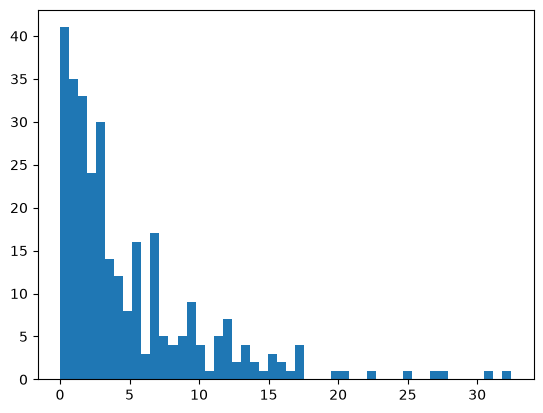

mean: 4.938116079775326 (difference: -1.2377 %)


In [11]:
#Sample 300 values once (you do not need to change this code block)
N = 300 #samples
l = 0.2 # lambda: parameter of exponential distribution
mean = 1/l # formula to compute mean of exponential distribution

def sampleFromExponential(l,N):
    return np.random.exponential(scale=1/l,size=N)

samples = sampleFromExponential(l,N) #gets a few samples from the exponential distribution

plt.figure()
plt.hist(samples, bins=50)
plt.show()

sample_mean = np.mean(samples)
print(f"mean: {sample_mean} (difference: {100*(sample_mean-mean)/mean:.04f} %)")

**A)** Modify the code below to draw 300 samples from this distribution **10,000 times each**. Sum up the 300 samples every time and collect the 10000 sums in a list/array. Note that these sums follow a different distribution (not exponential). **[2.5p]**

100%|██████████| 10000/10000 [00:00<00:00, 29451.01it/s]


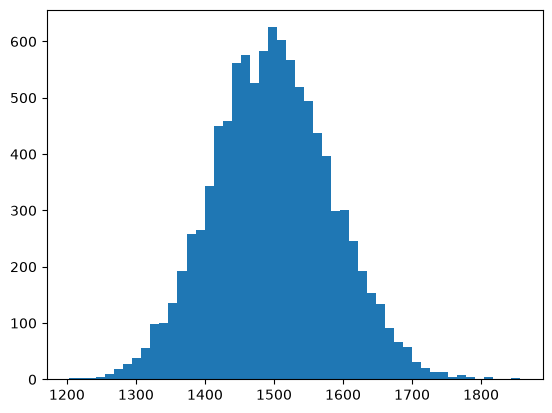

In [13]:
# [SOLUTION]
#Sample many times from the same (here: exponential) distribution 
R = 10000 #number of repetitions

sums = []
for r in tqdm(range(R)): #for each repetition
    sums.append(np.sum(sampleFromExponential(l, N)))

# plot new distribution
plt.figure()
plt.hist(sums, bins=50)
plt.show()


**B)** What distribution do you obtain? Report the unbiased values of mean, variance, and standard deviation of this new distribution. **[1p]**

In [17]:
#Mean and variance new distribution
print(f"mean: {np.mean(sums)}")
print(f"std: {np.std(sums, ddof=1)}")
print(f"var: {np.var(sums, ddof=1)}")

mean: 1498.4121243400027
std: 86.04772342367008
var: 7404.21070639642


In [ ]:
# It starts to look like a normal distribution with mean around 1500 and std around 86.

**Solution:**
- Normal Distribution
  - Mean: $\approx 50000$
  - Variance: roughly between 225000 and 275000
  - Standard deviation: roughly between 475 and 525

**C)** How do the mean and variance of the new distribution (mathematically) relate to the mean and variance of the original exponential distribution? What theorem is the basis for this 	behavior? **[1.5p]**

In [ ]:
# mu = 5
# std = 25
# E(samples) = 300 * 5 = 1500
# Var(samples) = 300 * 25 = 7500
# std(samples) = sqrt(7500) ~ 86.6

# Central limit theorem

**c)** The below code loads samples from **two independent random variables** (D1_samples and D2_samples). **[5p total]**

D1_samples
  N:    100
  mean: 6.0771
  var:  15.4726
  std:  3.9335
D2_samples
  N:    100
  mean: 6.7447
  var:  10.6175
  std:  3.2585


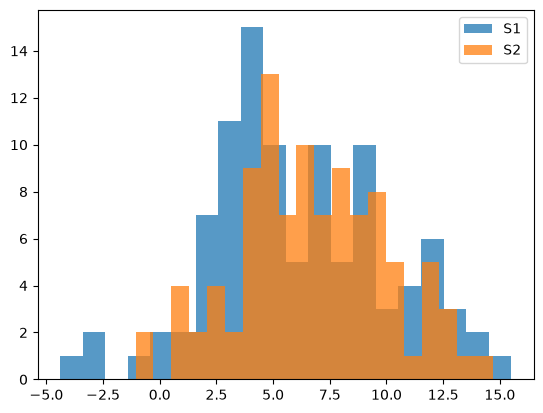

In [22]:
npz_dict = np.load("samples1.npz") # make sure your notebook finds this file!
D1_samples = npz_dict["D1_samples"] 
D2_samples = npz_dict["D2_samples"] 

for sampleList_name, sampleList in [("D1_samples",D1_samples), ("D2_samples",D2_samples)]:
    print(f"{sampleList_name}")
    print(f"  N:    {len(D1_samples)}") #length of array (= sample amount)
    print(f"  mean: {np.mean(sampleList):.04f}")
    print(f"  var:  {np.var(sampleList):.04f}")
    print(f"  std:  {np.std(sampleList):.04f}")

# plot subset distribution
bins = 20
plt.figure()
plt.hist(D1_samples, bins=bins, alpha=0.75, label="S1")
plt.hist(D2_samples, bins=bins, alpha=0.75, label="S2")
plt.legend() # plots labels
plt.show()



**A)** Argue whether you think the two random variables represent the same underlying distribution. **[1p]**

In [ ]:
# Visually they look similar, but the means and stds are slightly off, but there is a big difference in
# variance. I would say that they are similar enough considering that there is only 100 samples in each.

**B)** Look at the documentation of scipy's t-test for independent variables `ttest_ind`. What assumptions must hold to apply this specific t-test (in its default form)? Assume all requirements of this t-test are met. What is the null-hypothesis? **[1p]**

In [ ]:
# It assumes independency, normal distributions and equal variances.
# The null hypothesis is that the means of the distributions are equal.

**C)** Use `ttest_ind` to compute the p-value for the two sets of samples. Based on this 	p-value and your answer from B), argue whether the distributions are equal (mean and variance). **[3p]**

In [21]:
pvalue = scipy.stats.ttest_ind(D1_samples, D2_samples).pvalue
print(f"p-value (t-test): {pvalue}")

p-value (t-test): 0.19492676889634017


In [ ]:
# We can't make any conclusions with p ~ 0.2 and confidence of 0.5

**d)** Compute the p-value as you did in the previous task for the two sample sets in `samples2.npz`. What are your conclusions about the underlying distributions? **[1p]**

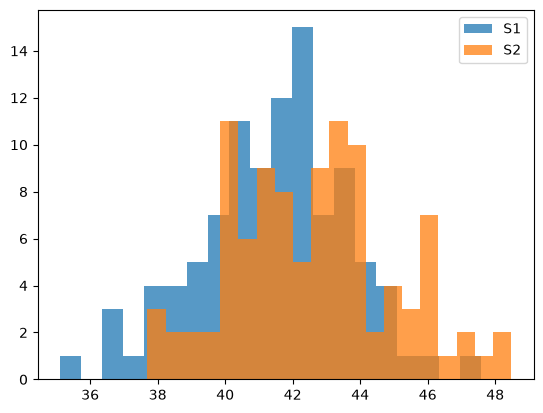

In [23]:
# Load the samples from the file
npz_dict = np.load("samples2.npz")
D1_samples = npz_dict["D1_samples"] 
D2_samples = npz_dict["D2_samples"] 

# plot subset distribution
bins = 20
plt.figure()
plt.hist(D1_samples, bins=bins, alpha=0.75, label="S1")
plt.hist(D2_samples, bins=bins, alpha=0.75, label="S2")
plt.legend() # plots labels
plt.show()

In [24]:
pvalue = scipy.stats.ttest_ind(D1_samples, D2_samples).pvalue #TODO
print(f"p-value (t-test): {pvalue}") 

p-value (t-test): 0.00031516534889536595


In [ ]:
# The H0 isn't correct under 0.5 confidence, the p value is too low therefore the means of these distributions are different.